## Trabajo Práctico 4 - Estimación de parámetros

---

Simular una muestra de dos variables aleatorias $X_1$ y $X_2$ que siguen una distribución normal estándar. Calcular la varianza muestral $s^2$. Considerar dos estimadores diferentes de la desviación estándar $t_1 = \sqrt{s^2}$ y $t_2 = \sqrt{\pi s^2/2}$. Repetir la simulación 1000 veces y construir los histogramas de frecuencia de $t_1$ y $t_2$. Decidir si los estimadores $t_1$ y $t_2$ son sesgados o no. Discutir porque el estimador de varianza $s^2$ no tiene sesgo pero el estimador de la desviación estándar $t_1 = \sqrt(s^2)$ es sesgado.


In [ ]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.stats import norm

In [ ]:
# Simulación de las variables aleatorias X = (X1, X2)

X = norm.rvs(size=2, random_state=125)
X


array([-0.69883694,  0.01062308])

#### Varianza muestral $S^{2}$:

La varianza muestral está dada por la siguiente fórmula:
$S^{2} = \frac{1}{n-1} \sum{(x_i - \bar{x})^2}$
Donde, n es el tamaño de la muestra, $x_i$ es el valor de una observación y $\bar{x}$ es el valor medio de todas las observaciones.
Esta varianza muestral contiene la corrección de Bessel y, en comparación con $S_n^{2}$, es un estimador sin sesgo porque su valor esperado es igual al valor de la varianza poblacional $\sigma^2$.

Para calcular $S^2$ (con la corrección de Bessel) tengo que agregarle ddof=1

In [ ]:
# Varianza uestral s^2
s2 = np.var(X, ddof=1)
s2

np.float64(0.9995932929433249)

In [ ]:
# Estimadores de la desviación estándar

t1 = np.sqrt(s2)
t2 = np.sqrt(np.pi*s2/2)

print('t1 =', t1, '||', 't2 =', t2)


t1 = 0.999796625791128 || t2 = 1.2530592455443557


Ahora hago 1000 simulaciones de las variables $X = (X_1, X_2)$. Obtendré 1000 valores de $S^2$ y , por lo tanto, 1000 valores de $t_1$ y $t_2$

In [ ]:
# 1000 simulaciones
n_sims = 1000

X = norm.rvs(size=[2,n_sims], random_state=125)

# Varianza muestral s2

s2 = np.var(X, ddof=1, axis=0)

# Estimadores de la desviación estandar

t1 = np.sqrt(s2)
t2 = np.sqrt(np.pi*s2/2)


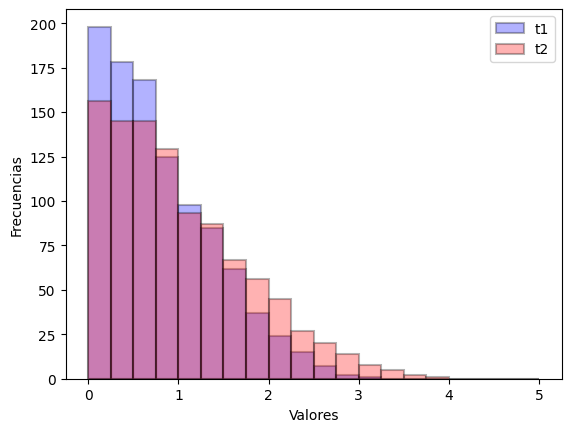

In [ ]:
# Histograma combinado de t1 y t2 con relleno transparente
plt.hist(t1, bins = 20, range = (0,5), label="t1", color='blue', alpha=0.3, edgecolor='black', linewidth=1.5)
plt.hist(t2, bins = 20, range = (0,5), label="t2", color='red', alpha=0.3, edgecolor='black', linewidth=1.5)

# Etiquetas y leyenda
plt.xlabel('t1, t2')
plt.ylabel('Frecuencias')
plt.legend()

# Mostrar gráfico
plt.show()

Quiero decidir si los estimadores $t_1$ y $t_2$ están o no sesgados. Para esto, quiero comparar los valores promedios de $t_1$ y $t_2$ con el valor esperado de la desviación estandar (poblacional?), que en este caso es 1 ya que $X = (X_1, X_2)$ sigue una distribución normal estándar.

$b = \text{Valor esperado} - \text{Valor promedio del estimador}$

Si esta resta da cercana a cero diremos que el estimador no está sesgado.

In [ ]:
# Valores promedios de t1 y t2

t1_mean = np.mean(t1)
t2_mean = np.mean(t2)
print('Valor medio de t1:', t1_mean)
print('Valor medio de t2:', t2_mean)

Valor medio de t1: 0.8111214626668889
Valor medio de t2: 1.0165899962404386


In [ ]:
# Cálculo del sesgo

b1 = 1 - t1_mean
b2 = 1- t2_mean

print('Sesgo del estimador t1:', b1)
print('Sesgo del estimador t2:', b2)


Sesgo del estimador t1: 0.1888785373331111
Sesgo del estimador t2: -0.016589996240438554


Comparando los valores del sesgo obtenidos, concluímos que $t_1$ es un estimador sesgado con un sesgo de 0.2 aproximadamente.  


¿Por qué $S^2$ es un estimador sin sesgo pero $\sqrt{S^2}$ si tiene sesgo?